# REECalc

Notebook for automatically calculating the composition of REE minerals

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Get samples and names from dataframe
data = pd.read_excel("/content/drive/MyDrive/Ycles/Monazita.xlsx")
samples = data.iloc[:24,:11].T # 24 oxides/elements and (18 - 2) samples, Fe2O3 column is 0 or NaN
samples.columns = samples.iloc[0]
oxides = samples.iloc[0,:]
elements = samples.iloc[1,:]

# Load weights (elements and oxides)
elem_weights = samples.iloc[2,:]
elem_weights.index = elements.values
molec_weights = samples.iloc[3,:]
molec_weights.index = oxides.values

# Load samples measures (oxides)
samples_df = samples.copy()
samples_df = samples_df.iloc[4:,:]
samples_df.columns = oxides.values

# Replace NaN values with 0.0
samples_df = samples_df.mask(samples_df.isna(), 0.0)
samples_df.head()

,P2O5,SiO2,CaO,FeO,La2O3,Ce2O3,Pr2O3,Nd2O3,Sm2O3,Eu2O3,...,Er2O3,Tm2O3,Yb2O3,Lu2O3,Y2O3,ThO2,UO2,PbO,F,Cl
Monazite webmineral,29.55,0.0,0.0,0.0,16.95,34.16,0.0,14.01,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,5.5,0.0,0.0,0.0,0.0
Cheralite webmineral,26.63,2.51,7.01,0.0,6.79,13.68,3.5,7.01,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,33.02,0.0,0.0,0.0,0.0
Huttonite webmineral,0.0,18.53,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,81.45,0.0,0.0,0.0,0.0
Xenotime Webmineral,38.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,61.4,0.0,0.0,0.0,0.0,0.0
Cheralite (ideal),30.66,0.0,12.13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,57.14,0.0,0.0,0.0,0.0


## 1. Units conversion and normalization

In [ ]:
samples_df.columns

Index(['P2O5', 'SiO2', 'CaO', 'FeO', 'La2O3', 'Ce2O3', 'Pr2O3', 'Nd2O3',
       'Sm2O3', 'Eu2O3', 'Gd2O3', 'Tb2O3', 'Dy2O3', 'Ho2O3', 'Er2O3', 'Tm2O3',
       'Yb2O3', 'Lu2O3', 'Y2O3', 'ThO2', 'UO2', 'PbO', 'F', 'Cl'],
      dtype='object')

In [ ]:
# Units conversion: oxides into molar proportions
samples_mols = samples_df.div(molec_weights, axis='columns')

# Get number of elements (cations/F/Cl) and anions
n_elems = [2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1] # F and Cl counted as 1
n_oxygens = [5, 2, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1, 0, 0]
n_elems = pd.Series(n_elems, index=samples_df.columns)
n_oxygens = pd.Series(n_oxygens, index=samples_df.columns)

# Calculate the molar proportions of cations and oxygen
elems_mols = samples_mols.mul(n_elems, axis="columns")
oxygens_mols = samples_mols.mul(n_oxygens, axis="columns")

,P2O5,SiO2,CaO,FeO,La2O3,Ce2O3,Pr2O3,Nd2O3,Sm2O3,Eu2O3,...,Er2O3,Tm2O3,Yb2O3,Lu2O3,Y2O3,ThO2,UO2,PbO,F,Cl
Monazite webmineral,0.416364,0.0,0.0,0.0,0.104046,0.208142,0.0,0.083275,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.02083,0.0,0.0,0.0,0.0
Cheralite webmineral,0.375221,0.041776,0.125007,0.0,0.04168,0.083354,0.021224,0.041667,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.125058,0.0,0.0,0.0,0.0
Huttonite webmineral,0.0,0.308407,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.308478,0.0,0.0,0.0,0.0
Xenotime Webmineral,0.54388,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.543822,0.0,0.0,0.0,0.0,0.0
Cheralite (ideal),0.432004,0.0,0.21631,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.216408,0.0,0.0,0.0,0.0
T. Al-Ani et al. (https://doi.org/10.4236/nr.2019.106016),0.323933,0.062081,0.019973,0.000418,0.158555,0.017548,0.056759,0.009213,0.005506,0.0,...,0.0,0.0,0.0,0.0,0.08423,0.000985,0.003333,0.086918,0.027371,0.000564
Monazite Ycles,0.408657,0.003628,0.013339,0.001754,0.08072,0.225313,0.024414,0.073871,0.004548,0.0,...,0.0,0.000067,0.000543,0.0,0.000868,0.000371,0.0,0.0,0.091641,0.000621


In [ ]:
# Calculate the anionic sum for normalization: number of oxygens + (F + Cl)
total_oxygen = oxygens_mols.sum(axis=1)
total_halogens = (
    elems_mols["F"] + elems_mols["Cl"]
)

# Corrected anion proportions (Excel convention)
total_anions = total_oxygen + total_halogens / 2

# Normalization factor: 4 anions
normalization_factor = 4 / total_anions.replace(0, np.nan)

# Calculate atoms per formula unit (apfu)
samples_apfu = elems_mols.mul(
    normalization_factor,
    axis="index"
)

# Replace oxide names with element names
samples_apfu.columns = elements.values

samples_apfu.head()

,P,Si,Ca,Fe,La,Ce,Pr,Nd,Sm,Eu,...,Er,Tm,Yb,Lu,Y,Th,U,Pb,F,Cl
Monazite webmineral,0.993848,0.0,0.0,0.0,0.248355,0.496829,0.0,0.198774,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.049721,0.0,0.0,0.0,0.0
Cheralite webmineral,0.894121,0.099548,0.297881,0.0,0.09932,0.198627,0.050575,0.099289,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.298002,0.0,0.0,0.0,0.0
Huttonite webmineral,0.0,0.999884,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.000116,0.0,0.0,0.0,0.0
Xenotime Webmineral,1.00004,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.999934,0.0,0.0,0.0,0.0,0.0
Cheralite (ideal),0.999353,0.0,0.500388,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.500616,0.0,0.0,0.0,0.0


## 2. Calculate structural formulae

Consider the structural formula: $AXW_4$
- A: P, Si
- X: ETR, Y, Ca, Th, U, Pb e Fe
- W: O, F, Cl

In [ ]:
# Site X
site_X = ["P", "Si"]

# Site A: all remaining cations
site_A = [
    col for col in samples_apfu.columns
    if col not in ["P", "Si", "F", "Cl"]
]

# Create structural formula summary
formula_df = pd.DataFrame(index=samples_apfu.index)

formula_df["X"] = samples_apfu[site_X].sum(axis=1)
formula_df["A"] = samples_apfu[site_A].sum(axis=1)

# Anion site, following the spreadsheet
formula_df["F"] = samples_apfu["F"]
formula_df["Cl"] = samples_apfu["Cl"]
formula_df["O"] = 4 - formula_df["F"] - formula_df["Cl"]

formula_df["W"] = (
    formula_df["O"]
    + formula_df["F"]
    + formula_df["Cl"]
)

formula_df.round(3)

,X,A,F,Cl,O,W
Monazite webmineral,0.993848,0.993679,0.0,0.0,4.0,4.0
Cheralite webmineral,0.993669,1.043694,0.0,0.0,4.0,4.0
Huttonite webmineral,0.999884,1.000116,0.0,0.0,4.0,4.0
Xenotime Webmineral,1.00004,0.999934,0.0,0.0,4.0,4.0
Cheralite (ideal),0.999353,1.001003,0.0,0.0,4.0,4.0
T. Al-Ani et al. (https://doi.org/10.4236/nr.2019.106016),0.987703,1.137459,0.070036,0.001443,3.928521,4.0
Monazite Ycles,0.964082,1.002252,0.214292,0.001451,3.784257,4.0


In [ ]:
# ETR, Y, Ca, Th, U, Pb e Fe
samples_apfu[site_A]

,Ca,Fe,La,Ce,Pr,Nd,Sm,Eu,Gd,Tb,Dy,Ho,Er,Tm,Yb,Lu,Y,Th,U,Pb
Monazite webmineral,0.0,0.0,0.248355,0.496829,0.0,0.198774,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.049721,0.0,0.0
Cheralite webmineral,0.297881,0.0,0.09932,0.198627,0.050575,0.099289,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.298002,0.0,0.0
Huttonite webmineral,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000116,0.0,0.0
Xenotime Webmineral,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.999934,0.0,0.0,0.0
Cheralite (ideal),0.500388,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.500616,0.0,0.0
T. Al-Ani et al. (https://doi.org/10.4236/nr.2019.106016),0.051104,0.001068,0.4057,0.044901,0.14523,0.023574,0.014088,0.0,0.002823,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.215523,0.00252,0.008528,0.222399
Monazite Ycles,0.031191,0.004101,0.188755,0.526868,0.057088,0.17274,0.010635,0.0,0.0,0.000882,0.005667,0.0,0.0,0.000158,0.00127,0.0,0.00203,0.000868,0.0,0.0


In [ ]:
# P, Si
samples_apfu[site_X]

,P,Si
Monazite webmineral,0.993848,0.0
Cheralite webmineral,0.894121,0.099548
Huttonite webmineral,0.0,0.999884
Xenotime Webmineral,1.00004,0.0
Cheralite (ideal),0.999353,0.0
T. Al-Ani et al. (https://doi.org/10.4236/nr.2019.106016),0.828855,0.158848
Monazite Ycles,0.955597,0.008484


In [ ]:
# Metadata overview
print(pd.DataFrame({
    "Oxide": samples_df.columns,
    "Element": elements.values,
    "Molecular weight": molec_weights.reindex(
        samples_df.columns
    ).values,
    "Number of elements": n_elems.values,
    "Number of oxygens": n_oxygens.values
}))

    Oxide Element Molecular weight  Number of elements  Number of oxygens
0    P2O5       P          141.943                   2                  5
1    SiO2      Si           60.083                   1                  2
2     CaO      Ca           56.077                   1                  1
3     FeO      Fe           71.844                   1                  1
4   La2O3      La          325.817                   2                  3
5   Ce2O3      Ce          328.237                   2                  3
6   Pr2O3      Pr          329.817                   2                  3
7   Nd2O3      Nd          336.477                   2                  3
8   Sm2O3      Sm          348.717                   2                  3
9   Eu2O3      Eu          351.965                   2                  3
10  Gd2O3      Gd          362.497                   2                  3
11  Tb2O3      Tb          365.857                   2                  3
12  Dy2O3      Dy          372.997    

## 3. Plotting

The diagram has three end-members:
- Huttonite: Si (apfu), no vértice superior.
- Monazite: soma dos ETR (apfu), no vértice inferior esquerdo.
- Cheralite: Ca (apfu), no vértice inferior direito.

In [ ]:
# Rare earth elements (including Y)
ree = [
    "La", "Ce", "Pr", "Nd", "Sm", "Eu",
    "Gd", "Tb", "Dy", "Ho", "Er",
    "Tm", "Yb", "Lu", "Y"
]

# Ternary end-members
ternary = pd.DataFrame(index=samples_apfu.index)

ternary["Monazite"] = samples_apfu[ree].sum(axis=1)
ternary["Cheralite"] = samples_apfu["Ca"]
ternary["Huttonite"] = samples_apfu["Si"]

# Normalize to sum to 1
ternary = ternary.div(
    ternary.sum(axis=1).replace(0, np.nan),
    axis=0
)

ternary.head()

,Monazite,Cheralite,Huttonite
Monazite webmineral,1.0,0.0,0.0
Cheralite webmineral,0.529803,0.352422,0.117775
Huttonite webmineral,0.0,0.0,1.0
Xenotime Webmineral,1.0,0.0,0.0
Cheralite (ideal),0.0,1.0,0.0


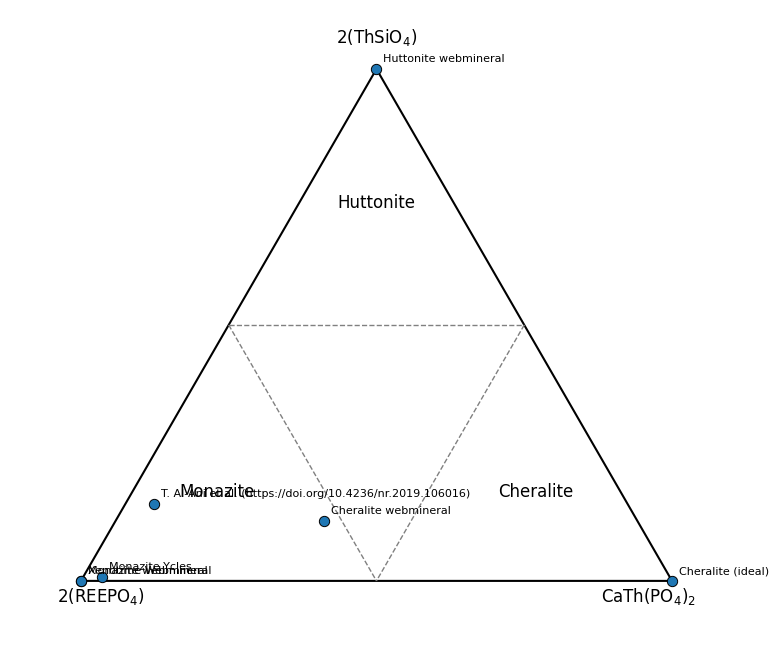

In [ ]:
# ============================================================
# TERNARY COORDINATES
# ============================================================

def ternary_to_xy(monazite, cheralite, huttonite):
    x = cheralite + 0.5 * huttonite
    y = (np.sqrt(3) / 2) * huttonite
    return x, y


# ============================================================
# CREATE TERNARY DIAGRAM
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

h = np.sqrt(3) / 2

# Triangle vertices
vertices = np.array([
    [0, 0],       # Monazite
    [1, 0],       # Cheralite
    [0.5, h],     # Huttonite
    [0, 0]
])

ax.plot(
    vertices[:, 0],
    vertices[:, 1],
    color="black",
    linewidth=1.5
)

# ============================================================
# CLASSIFICATION GRID
# ============================================================

# 50% Huttonite boundary
ax.plot(
    [0.25, 0.75],
    [h / 2, h / 2],
    linestyle="--",
    color="gray",
    linewidth=1
)

# Boundary between Monazite and Cheralite
# Left midpoint -> bottom midpoint
ax.plot(
    [0.25, 0.5],
    [h / 2, 0],
    linestyle="--",
    color="gray",
    linewidth=1
)

# Right midpoint -> bottom midpoint
ax.plot(
    [0.75, 0.5],
    [h / 2, 0],
    linestyle="--",
    color="gray",
    linewidth=1
)

# ============================================================
# FIELD LABELS
# ============================================================

ax.text(
    0.5, 0.64,
    "Huttonite",
    ha="center",
    va="center",
    fontsize=12
)

ax.text(
    0.23, 0.15,
    "Monazite",
    ha="center",
    va="center",
    fontsize=12
)

ax.text(
    0.77, 0.15,
    "Cheralite",
    ha="center",
    va="center",
    fontsize=12
)

# ============================================================
# END-MEMBER LABELS
# ============================================================

ax.text(
    0.5, h + 0.045,
    r"$2(\mathrm{ThSiO_4})$",
    ha="center",
    fontsize=12
)

ax.text(
    -0.04, -0.035,
    r"$2(\mathrm{REEPO_4})$",
    ha="left",
    fontsize=12
)

ax.text(
    1.04, -0.035,
    r"$\mathrm{CaTh(PO_4)_2}$",
    ha="right",
    fontsize=12
)

# ============================================================
# PLOT SAMPLES
# ============================================================

x, y = ternary_to_xy(
    ternary["Monazite"],
    ternary["Cheralite"],
    ternary["Huttonite"]
)

ax.scatter(
    x,
    y,
    s=55,
    color="tab:blue",
    edgecolors="black",
    linewidths=0.7,
    zorder=3
)

# Optional sample labels
for sample, xi, yi in zip(ternary.index, x, y):
    if np.isfinite(xi) and np.isfinite(yi):
        ax.annotate(
            str(sample),
            (xi, yi),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

# ============================================================
# FORMAT
# ============================================================

ax.set_aspect("equal")

ax.set_xlim(-0.12, 1.12)
ax.set_ylim(-0.10, h + 0.10)

ax.axis("off")

plt.tight_layout()
plt.show()